In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch

torch.random.manual_seed(0)

In [3]:
import numpy as np
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

# MNIST

In [ ]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

11493376/11490434 [==============================] - 0s 0us/step


In [ ]:
print(f'Train -> x: {x_train.shape}')
print(f'         y: {y_train.shape}')
print(f'Test ->  x: {x_test.shape}')
print(f'         y: {y_test.shape}')

Train -> x: (60000, 28, 28)
         y: (60000,)
Test ->  x: (10000, 28, 28)
         y: (10000,)


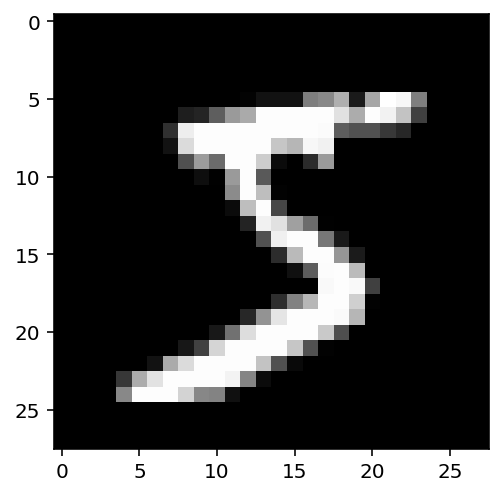

In [ ]:
# Veamos una muestra
plt.imshow(x_train[0], 'gray');

In [ ]:
y_train[0]

5

In [ ]:
# Veamos todas las clases del conjunto de entrenamiento
set(y_train)

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9}

## Normalizamos los datos

In [ ]:
#Los datos que están en el rango [0, 255] los transformamos al rango [0, 1]
x_train = x_train / 255.
x_test = x_test / 255.

In [ ]:
#Los datos que están en el rango [0, 1] los transformamos al rango [-1, 1]
mean = 0.5
std = 0.5

x_train = (x_train - mean) / std
x_test = (x_test - mean) / std

## Agregamos un canal a los datos

In [ ]:
x_train = x_train.reshape((-1, 1, 28, 28))
x_test = x_test.reshape((-1, 1, 28, 28))

In [ ]:
x_train.shape

(60000, 1, 28, 28)

In [ ]:
x_test.shape

(10000, 1, 28, 28)

## Cargamos los datos para el entrenamiento

In [ ]:
train_dataset = list(zip(x_train, y_train))

test_dataset = list(zip(x_test, y_test))

In [ ]:
#Batch size
bs = 64

In [ ]:
train_dataset_loader = torch.utils.data.DataLoader(dataset=train_dataset,
                                                   batch_size=bs,
                                                   shuffle=True)

In [ ]:
test_dataset_loader = torch.utils.data.DataLoader(dataset=test_dataset,
                                                  batch_size=bs,
                                                  shuffle=False)

## Definimos un modelo

In [ ]:
def save_weights(model, optimizer, model_file, optimizer_file):
  torch.save(model.state_dict(), model_file)
  torch.save(optimizer.state_dict(), optimizer_file)

def reset_weights(model, optimizer, model_file, optimizer_file):
  model.load_state_dict(torch.load(model_file))

  optimizer.load_state_dict(torch.load(optimizer_file))

  return model, optimizer

In [ ]:
device_condition = 'cuda' if torch.cuda.is_available() else 'cpu'

device = torch.device(device_condition)

device

device(type='cpu')

In [ ]:
class NeuralNet(torch.nn.Module):
  def __init__(self):
    super(NeuralNet, self).__init__()

    self.convolutional_1 = torch.nn.Conv2d(1, 16, kernel_size=3, padding=1)
    self.max_pooling_1 = torch.nn.MaxPool2d(kernel_size=2)
    self.relu_1 = torch.nn.ReLU()
    self.convolutional_2 = torch.nn.Conv2d(16, 32, kernel_size=3, padding=1)
    self.max_pooling_2 = torch.nn.MaxPool2d(kernel_size=2)
    self.relu_2 = torch.nn.ReLU()
    self.convolutional_3 = torch.nn.Conv2d(32, 64, kernel_size=3)
    self.relu_3 = torch.nn.ReLU()
    self.dense_1 = torch.nn.Linear(5*5*64, 256)
    self.relu_4 = torch.nn.ReLU()
    self.dense_2 = torch.nn.Linear(256, 10)

  def forward(self, x):
    x = self.convolutional_1(x)
    x = self.max_pooling_1(x)
    x = self.relu_1(x)
    x = self.convolutional_2(x)
    x = self.max_pooling_2(x)
    x = self.relu_2(x)
    x = self.convolutional_3(x)
    x = self.relu_3(x)
    x = x.view(-1, 5*5*64) #Flatten
    x = self.dense_1(x)
    x = self.relu_4(x)
    x = self.dense_2(x)

    return torch.nn.functional.log_softmax(x, dim=-1)

def create_model():
  torch.cuda.empty_cache()

  model = NeuralNet()

  return model

In [ ]:
lr = 0.001
momentum = 0.9

model = create_model()

loss_function = torch.nn.NLLLoss(reduction="none")
optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)

model = model.to(device)

In [ ]:
model.eval()

NeuralNet(
  (convolutional_1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (max_pooling_1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu_1): ReLU()
  (convolutional_2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (max_pooling_2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu_2): ReLU()
  (convolutional_3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (relu_3): ReLU()
  (dense_1): Linear(in_features=1600, out_features=256, bias=True)
  (relu_4): ReLU()
  (dense_2): Linear(in_features=256, out_features=10, bias=True)
)

In [ ]:
import torchsummary

torchsummary.summary(model.to(device), (1, 28, 28), device=device_condition)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 28, 28]             160
         MaxPool2d-2           [-1, 16, 14, 14]               0
              ReLU-3           [-1, 16, 14, 14]               0
            Conv2d-4           [-1, 32, 14, 14]           4,640
         MaxPool2d-5             [-1, 32, 7, 7]               0
              ReLU-6             [-1, 32, 7, 7]               0
            Conv2d-7             [-1, 64, 5, 5]          18,496
              ReLU-8             [-1, 64, 5, 5]               0
            Linear-9                  [-1, 256]         409,856
             ReLU-10                  [-1, 256]               0
           Linear-11                   [-1, 10]           2,570
Total params: 435,722
Trainable params: 435,722
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/

## Entrenamiento

In [ ]:
%mkdir -p my_model

In [ ]:
def get_accuracy(predictions, y):
  comparison = predictions.max(dim=1).indices == y
  accuracy = torch.sum(comparison) / y.shape[0]
  accuracy = accuracy

  return accuracy

In [ ]:
def train_model(model, loss_function, optimizer, epochs, train_dataset_loader, test_dataset_loader):
  train_losses = []
  test_losses = []

  train_accuracies = []
  test_accuracies = []

  for epoch in range(epochs):
    train_loss = torch.tensor(0, dtype=torch.float32)
    test_loss = torch.tensor(0, dtype=torch.float32)

    train_accuracy = torch.tensor(0, dtype=torch.float32)
    test_accuracy = torch.tensor(0, dtype=torch.float32)

    ###################################################################################################################

    #Establecer el modelo en modo entrenamiento
    model.train()

    #Número de batches
    nb = len(train_dataset_loader)

    #Número de registros
    n_rows = len(train_dataset_loader.dataset)

    for batch_x_train, batch_y_train in train_dataset_loader:
      batch_x_train = batch_x_train.to(device).to(torch.float32)
      batch_y_train = batch_y_train.to(device).to(torch.int64)

      #PyTorch acumula gradientes, por eso necesitamos eliminarlas antes de cada instancia
      model.zero_grad()

      batch_train_predictions = model(batch_x_train)

      batch_train_loss = loss_function(batch_train_predictions, batch_y_train)
      #Sacamos la media para realizar el backward
      batch_train_loss.mean().backward()

      optimizer.step()

      train_loss += batch_train_loss.sum()

      train_accuracy += get_accuracy(batch_train_predictions, batch_y_train)
    
    train_loss /= n_rows
    #Necesitamos usar detach porque esta sección no se ha ejecutado con torch.no_grad()
    #Eso implica que el tensor require grad
    train_loss = train_loss.detach().numpy()
    
    train_accuracy /= nb
    train_accuracy = train_accuracy.numpy()

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    ###################################################################################################################  
    
    #Establecer el modelo en modo prueba
    model.eval()

    #Número de batches
    nb = len(test_dataset_loader)

    #Número de registros
    n_rows = len(test_dataset_loader.dataset)
    
    with torch.no_grad():
      for batch_x_test, batch_y_test in test_dataset_loader:
        batch_x_test = batch_x_test.to(device).to(torch.float32)
        batch_y_test = batch_y_test.to(device).to(torch.int64)

        batch_test_predictions = model(batch_x_test)

        batch_test_loss = loss_function(batch_test_predictions, batch_y_test)
        test_loss += batch_test_loss.sum()

        test_accuracy += get_accuracy(batch_test_predictions, batch_y_test)
      
      test_loss /= n_rows
      test_loss = test_loss.numpy()

      test_accuracy /= nb
      test_accuracy = test_accuracy.numpy()

      test_losses.append(test_loss)
      test_accuracies.append(test_accuracy)
    
    ###################################################################################################################
    
    print("Epoch {}/{}\n----> loss: {:.4f} - accuracy: {:.4f} - val_loss: {:.4f} - val_accuracy: {:.4f}".format(epoch+1, epochs, train_loss, train_accuracy, test_loss, test_accuracy))

    save_weights(model, optimizer, "my_model/model.pt", "my_model/optimizer.pt")
  
  return train_losses, test_losses, train_accuracies, test_accuracies

In [ ]:
def show_results(train_losses, test_losses, train_accuracies, test_accuracies):
  fig, axes = plt.subplots(1, 2, figsize=(14,4))
  ax1, ax2 = axes
  ax1.plot(train_losses, label='train')
  ax1.plot(test_losses, label='test')
  ax1.set_xlabel('epoch'); ax1.set_ylabel('loss')
  ax2.plot(train_accuracies, label='train')
  ax2.plot(test_accuracies, label='test')
  ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy')
  for ax in axes: ax.legend()

In [ ]:
epochs = 5

train_losses, test_losses, train_accuracies, test_accuracies = train_model(model, loss_function, optimizer, epochs, train_dataset_loader, test_dataset_loader)

Epoch 1/5
----> loss: 1.4391 - accuracy: 0.6008 - val_loss: 0.3327 - val_accuracy: 0.9029
Epoch 2/5
----> loss: 0.2435 - accuracy: 0.9269 - val_loss: 0.1603 - val_accuracy: 0.9528
Epoch 3/5
----> loss: 0.1381 - accuracy: 0.9585 - val_loss: 0.1037 - val_accuracy: 0.9686
Epoch 4/5
----> loss: 0.1019 - accuracy: 0.9687 - val_loss: 0.0834 - val_accuracy: 0.9751
Epoch 5/5
----> loss: 0.0828 - accuracy: 0.9752 - val_loss: 0.0671 - val_accuracy: 0.9798


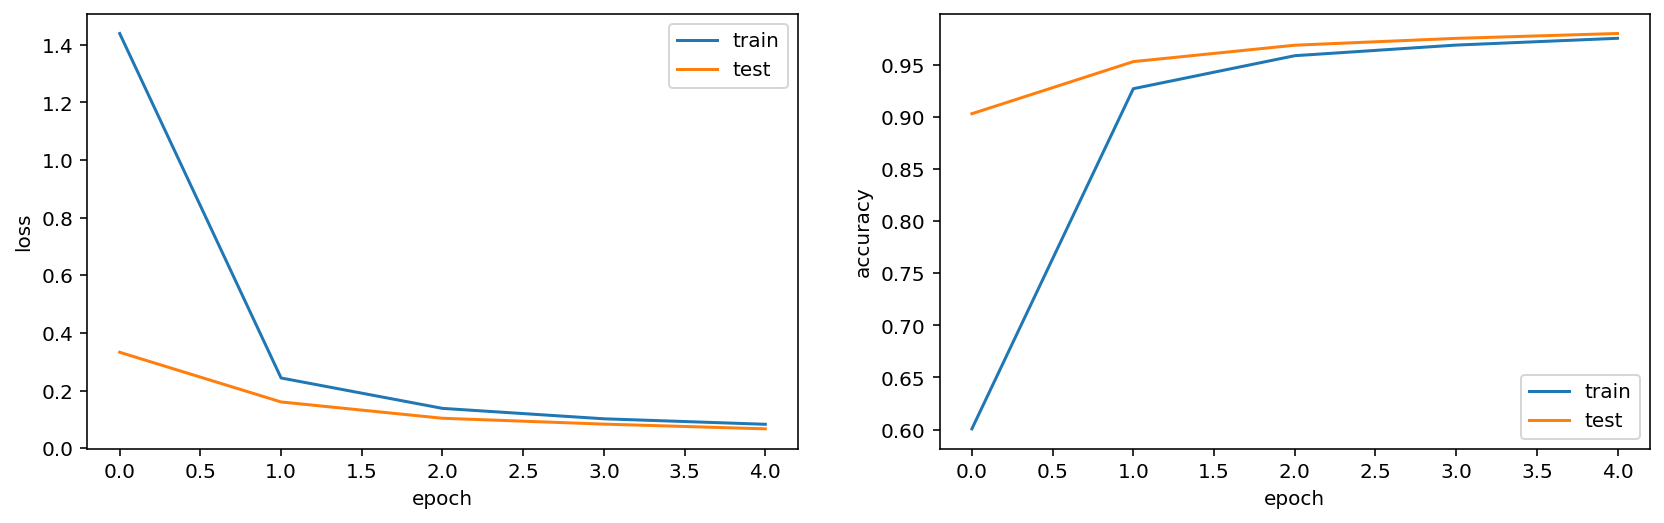

In [ ]:
show_results(train_losses, test_losses, train_accuracies, test_accuracies)

## Visualizando algunas predicciones

In [ ]:
batch_x_test, batch_y_test = next(iter(test_dataset_loader))

with torch.no_grad():
  batch_x_test = batch_x_test.to(device).to(torch.float32)
  batch_y_test = batch_y_test.to(device).to(torch.int64)
  
  predictions = model(batch_x_test)

  predictions = torch.nn.functional.softmax(predictions, dim=-1)

In [ ]:
batch_x_test = batch_x_test.numpy()
batch_y_test = batch_y_test.numpy().tolist()
predictions = predictions.max(dim=1).indices.numpy().tolist()

In [ ]:
np.random.seed(0)

random_samples_from_batch = np.random.randint(len(batch_y_test), size=5)

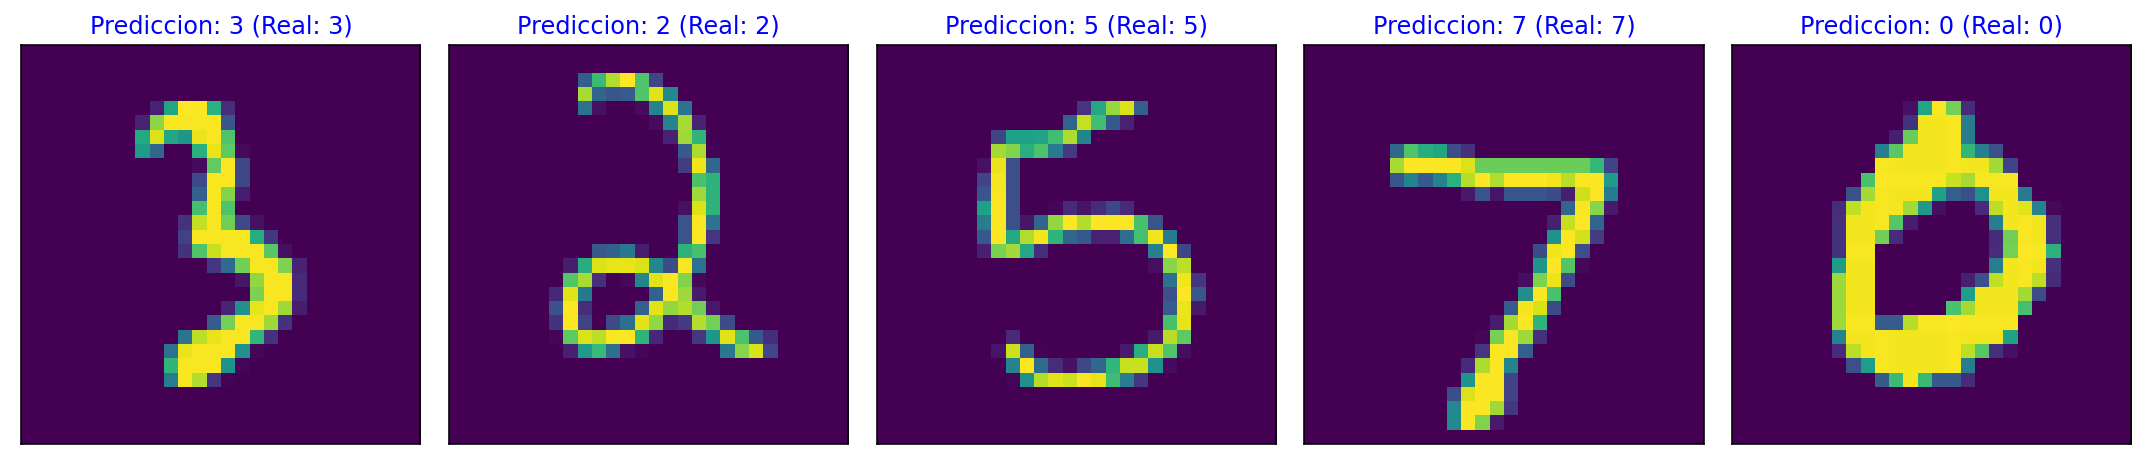

In [ ]:
figure = plt.figure(figsize=(15, 8))

for i, index in enumerate(random_samples_from_batch):
  ax = figure.add_subplot(1, 5, i + 1, xticks=[], yticks=[])
  
  image = batch_x_test[index].reshape(28, 28)
  ax.imshow(image, cmap="viridis")

  true_label = batch_y_test[index]
  predicted_label = predictions[index]
  
  condition_for_color = "blue" if predicted_label == true_label else "red"
  ax.set_title("Prediccion: {} (Real: {})".format(predicted_label, true_label),
                                                  color=(condition_for_color))

figure.tight_layout()

## Reanudamos el Entrenamiento

In [ ]:
model = create_model()

loss_function = torch.nn.NLLLoss(reduction="none")
optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)

In [ ]:
model, optimizer = reset_weights(model, optimizer, "my_model/model.pt", "my_model/optimizer.pt")

model = model.to(device)

In [ ]:
import torchsummary

torchsummary.summary(model.to(device), (1, 28, 28), device=device_condition)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 28, 28]             160
         MaxPool2d-2           [-1, 16, 14, 14]               0
              ReLU-3           [-1, 16, 14, 14]               0
            Conv2d-4           [-1, 32, 14, 14]           4,640
         MaxPool2d-5             [-1, 32, 7, 7]               0
              ReLU-6             [-1, 32, 7, 7]               0
            Conv2d-7             [-1, 64, 5, 5]          18,496
              ReLU-8             [-1, 64, 5, 5]               0
            Linear-9                  [-1, 256]         409,856
             ReLU-10                  [-1, 256]               0
           Linear-11                   [-1, 10]           2,570
Total params: 435,722
Trainable params: 435,722
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/

In [ ]:
epochs = 5

train_losses, test_losses, train_accuracies, test_accuracies = train_model(model, loss_function, optimizer, epochs, train_dataset_loader, test_dataset_loader)

Epoch 1/5
----> loss: 0.0718 - accuracy: 0.9782 - val_loss: 0.0616 - val_accuracy: 0.9812
Epoch 2/5
----> loss: 0.0635 - accuracy: 0.9806 - val_loss: 0.0574 - val_accuracy: 0.9812
Epoch 3/5
----> loss: 0.0569 - accuracy: 0.9831 - val_loss: 0.0543 - val_accuracy: 0.9831
Epoch 4/5
----> loss: 0.0525 - accuracy: 0.9843 - val_loss: 0.0507 - val_accuracy: 0.9839
Epoch 5/5
----> loss: 0.0480 - accuracy: 0.9853 - val_loss: 0.0438 - val_accuracy: 0.9856


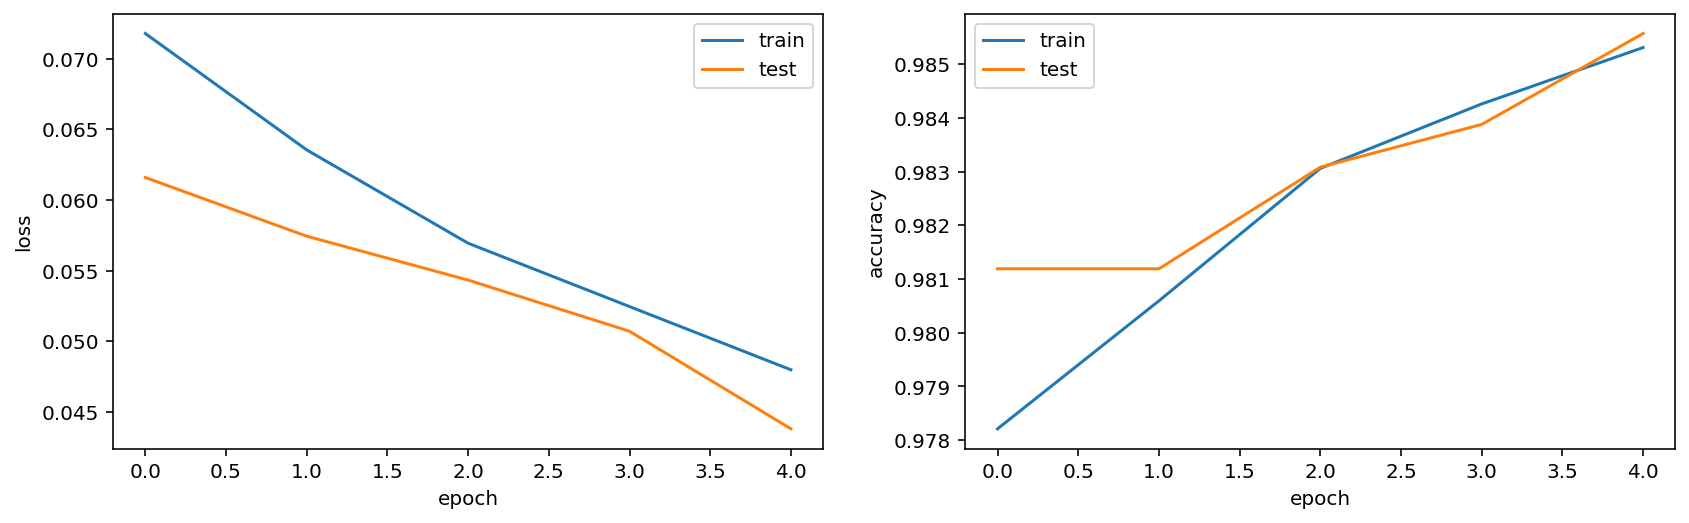

In [ ]:
show_results(train_losses, test_losses, train_accuracies, test_accuracies)

## Visualizando algunas predicciones

In [ ]:
batch_x_test, batch_y_test = next(iter(test_dataset_loader))

with torch.no_grad():
  batch_x_test = batch_x_test.to(device).to(torch.float32)
  batch_y_test = batch_y_test.to(device).to(torch.int64)
  
  predictions = model(batch_x_test)

  predictions = torch.nn.functional.softmax(predictions, dim=-1)

In [ ]:
batch_x_test = batch_x_test.numpy()
batch_y_test = batch_y_test.numpy().tolist()
predictions = predictions.max(dim=1).indices.numpy().tolist()

In [ ]:
np.random.seed(10)

random_samples_from_batch = np.random.randint(len(batch_y_test), size=5)

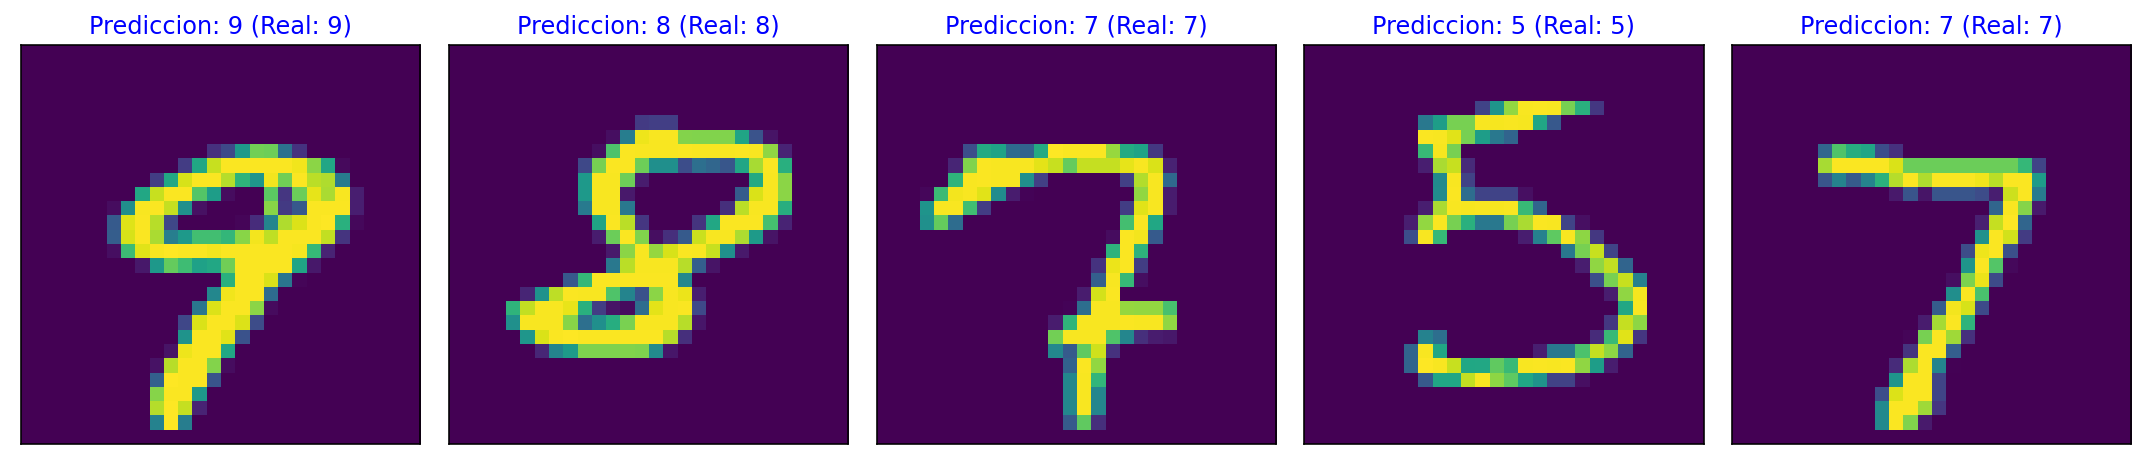

In [ ]:
figure = plt.figure(figsize=(15, 8))

for i, index in enumerate(random_samples_from_batch):
  ax = figure.add_subplot(1, 5, i + 1, xticks=[], yticks=[])
  
  image = batch_x_test[index].reshape(28, 28)
  ax.imshow(image, cmap="viridis")

  true_label = batch_y_test[index]
  predicted_label = predictions[index]
  
  condition_for_color = "blue" if predicted_label == true_label else "red"
  ax.set_title("Prediccion: {} (Real: {})".format(predicted_label, true_label),
                                                  color=(condition_for_color))

figure.tight_layout()

## Revisamos las Métricas

In [ ]:
labels = list()
predictions = list()

with torch.no_grad():
  for batch_x_test, batch_y_test in test_dataset_loader:
    batch_x_test = batch_x_test.to(device).to(torch.float32)
    batch_y_test = batch_y_test.to(device).to(torch.int64)

    batch_test_predictions = model(batch_x_test)

    batch_test_predictions = torch.nn.functional.softmax(batch_test_predictions, dim=-1)
    
    batch_test_predictions = batch_test_predictions.max(dim=1).indices

    labels.append(batch_y_test)
    predictions.append(batch_test_predictions)

labels = torch.cat(labels, dim=0)
predictions = torch.cat(predictions, dim=0)

In [ ]:
labels = labels.numpy()
predictions = predictions.numpy()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(labels, predictions, digits=4))

              precision    recall  f1-score   support

           0     0.9790    0.9969    0.9879       980
           1     0.9964    0.9885    0.9925      1135
           2     0.9826    0.9864    0.9845      1032
           3     0.9852    0.9891    0.9872      1010
           4     0.9928    0.9817    0.9872       982
           5     0.9865    0.9843    0.9854       892
           6     0.9895    0.9823    0.9859       958
           7     0.9834    0.9825    0.9830      1028
           8     0.9715    0.9805    0.9760       974
           9     0.9871    0.9822    0.9846      1009

    accuracy                         0.9855     10000
   macro avg     0.9854    0.9854    0.9854     10000
weighted avg     0.9855    0.9855    0.9855     10000

